# Projection head training

Train the shared DINO projection head with group-separated episodes and normalized mean prototypes in both training and inference. Only known training images receive gradients; new SKU registration requires no head training.
Raw backbone vectors persist in `var/embed_cache/` and are reused when changing or retraining the head.


## 1. Đọc cấu hình chung `.env`

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True
nb_dir = Path.cwd() if (Path.cwd() / 'notebook_utils.py').is_file() else Path.cwd() / 'notebooks'
assert (nb_dir / 'notebook_utils.py').is_file(), 'Mở notebook từ thư mục dự án hoặc notebooks.'
sys.path.insert(0, str(nb_dir.resolve()))
from notebook_utils import load_workflow
run = load_workflow()

## 2. Kiểm tra Python và GPU

In [2]:
run.check_environment()

{'python': 'c:\\Users\\user\\miniconda3\\envs\\build_ML\\python.exe',
 'torch': '2.5.1+cu121',
 'cuda': True,
 'gpu': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU',
 'dataset': 'data\\dataset_v2',
 'profile': {'k_shot': 2, 'class_seed': 1, 'split_seed': 401},
 'output': 'var\\thesis_v4'}

In [3]:
# Existing backbone vectors survive kernel restarts and head retraining.
run.cache_info()

[]

## 3. Xem tham số trước khi train
Mặc định epoch/episode giống `run_all`. Đổi các tham số này trước khi train, không chọn theo test.

In [4]:
EPOCHS = 20
EPISODES = 300
run.show_config()

{'data_dir': 'data\\dataset_v2',
 'profile': {'k_shot': 2, 'class_seed': 1, 'split_seed': 401},
 'encoder': 'dinov2',
 'batch_size': 16,
 'alpha': 0.1,
 'target_risk': 0.04,
 'decision_rule': 'prototype_selective',
 'prototypes_per_sku': 1,
 'color_weight': 0.3,
 'vector_cache': 'var\\embed_cache',
 'head': 'var\\thesis_v4\\projection_head.pt',
 'bank': 'var\\thesis_v4\\prototypes.json',
 'calibration': 'var\\thesis_v4\\calibration.json'}

## 4. Train head
Trích đặc trưng → train theo episode → early stopping → lưu checkpoint tốt nhất. Có thể chạy lâu.
Nếu bị ngắt, chạy lại ô này: dùng cache và train lại từ đầu, không tiếp tục optimizer giữa epoch.
Chạy ô này sẽ train head mới và ghi đè head tại `RPV_HEAD_OUT`, giống `run_all --train-head`.

In [5]:
training_result = run.train(epochs=EPOCHS, episodes=EPISODES)
training_result

Đang chạy train-head (configured)...
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\user\.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
[train-head] splits={'protocol': 'known_unknown_70_30_v1', 'n_train_images': 2878, 'n_validation_images': 1887, 'n_known_classes': 17, 'n_train_classes': 17, 'n_novel_classes': 7, 'n_support_images': 34, 'n_calib_images': 1915, 'n_test_images': 1927, 'n_unknown_calib': 0, 'n_unknown_test': 4200, 'n_novel_support': 35, 'n_novel_query': 836}
[catalog-train] {'epoch': 0, 'train_loss'

{'checkpoint': 'var\\thesis_v4\\projection_head.pt',
 'best_epoch': 1,
 'best_val_acc': 0.7025472351102604}

## 5. Xem loss và accuracy validation

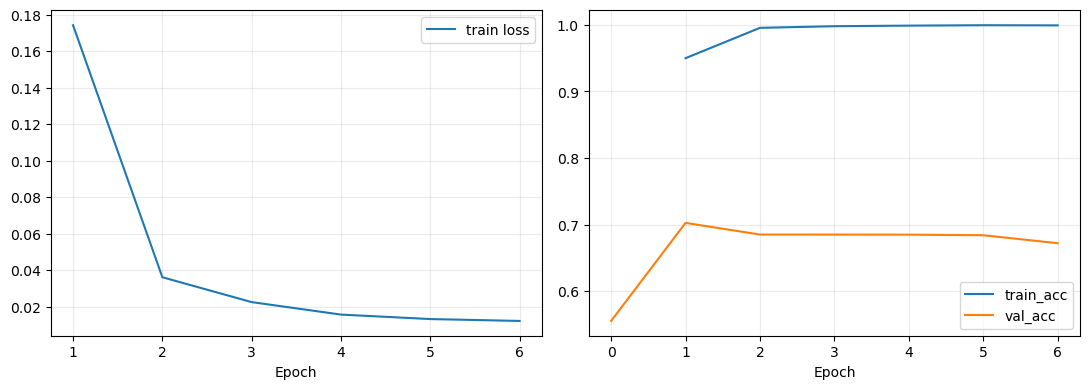

In [6]:
run.plot_training_history()

Tiếp theo: **03_calibration.ipynb**. File head mặc định là `var/thesis/projection_head.pt`, dùng được từ terminal.